# **Classification - Nature Scene Prediction**

* The company offers information to readers via mobile, web, social, magazine, and print platforms.

- They want to build a feature on their platform that classify the natural scene in the background of an image.

- The researchers have adopted a multidisciplinary approach to understanding the different aspects of understanding the natural scenes.

- The background of an image is manually identified from images in order to write any blog or post on it.

- This process is very slow, time-consuming, and labour-intensive.


- The company has hired you as data science consultants.
They want to automate the process of identifying natural scene from the background of an image to make it more efficient.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import PIL
import zipfile

In [ ]:
import tensorflow as tf
print(tf.__version__)

2.21.0


In [ ]:
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential
from tensorflow.python.keras.layers import Dense, Flatten, Conv2D

from tensorflow.keras.applications import ResNet50
from tensorflow.python.keras import optimizers
from tensorflow.python.keras.callbacks import EarlyStopping
from sklearn.metrics import accuracy_score


## **Loading the Data**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# extract the zip file

path_to_zip_file = "/content/drive/MyDrive/2026DS Plan/Coomputer vision/train.zip"
with zipfile.ZipFile(path_to_zip_file, 'r') as zip_ref:
  zip_ref.extractall('/content')

In [ ]:
# extract the zip file

path_to_zip_file = "/content/drive/MyDrive/2026DS Plan/Coomputer vision/test.zip"
with zipfile.ZipFile(path_to_zip_file, 'r') as zip_ref:
  zip_ref.extractall('/content')

We are loading the image data using keras functions called `image_dataset_from_directory`.

This will help us to extract the image label from its folder name.

We are specifying the batch_size as 32 and height and width of an image as 180.

In [ ]:
batch_size = 32
img_height = 180
img_width = 180

train_dir  ='./train'

train_ds = tf.keras.preprocessing.image_dataset_from_directory(
                                                              train_dir,
                                                              validation_split = 0.2,
                                                              subset = 'training',
                                                              seed = 123,
                                                              image_size =(img_height, img_width),
                                                              batch_size = batch_size
                                                              )


val_ds = tf.keras.preprocessing.image_dataset_from_directory(
                                                            train_dir,
                                                            validation_split = 0.2,
                                                            subset = "validation",
                                                            seed= 123,
                                                            image_size = (img_height, img_width),
                                                            batch_size = batch_size
                                                            )


Found 14034 files belonging to 6 classes.
Using 11228 files for training.
Found 14034 files belonging to 6 classes.
Using 2806 files for validation.


In [ ]:
class_names = os.listdir(train_dir)
class_names

['glacier', 'sea', 'street', 'forest', 'buildings', 'mountain']

In [ ]:
print(train_ds.class_names)

['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']


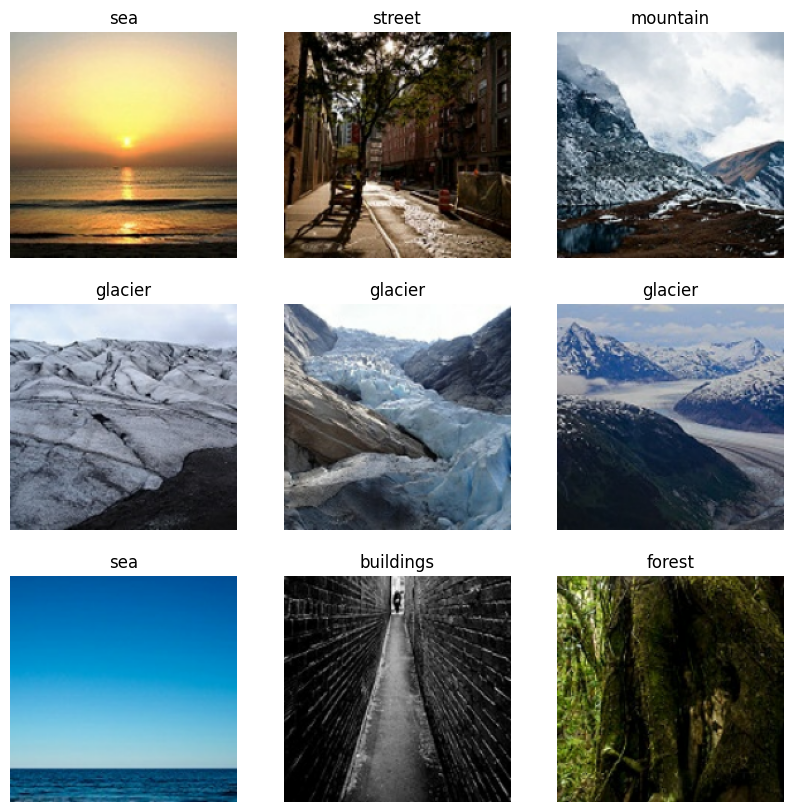

In [ ]:
# define class_names

class_names = ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']


#create features

plt.figure(figsize = [10,10])

#get one batch from training dataset  (1 = select from only one batch)
for images, labels in train_ds.take(1):

  #display  9 images
  for i in range(9):

    plt.subplot(3,3,i+1)

    #display images
    plt.imshow(images[i].numpy().astype("uint8"))

    # displaying title
    plt.title(class_names[labels[i]])

    plt.axis('off')

plt.show();

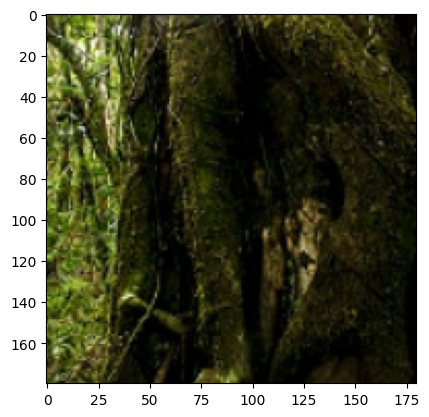

In [ ]:
plt.imshow(images[i].numpy().astype("uint8"))


* .numpy() -----	Converts TensorFlow tensor into NumPy array
* .astype("uint8") ------	Converts pixel data into 8-bit unsigned integers
* plt.imshow() ---------	Displays the image

* There are 6 sub-folders, each belonging to a scene.

* Each scene sub-folder contains images belonging to that scene.

* The dataset contains the images of the following natural scenes:
  - **Buildings:** This class contains images of different buildings.
  - **Forest:** This class contains images of different forests.
  - **glacier:** This class contains images of different glaciers.
   - **mountain:** This class contains images of different mountains.
  -  **sea:** This class contains Images of different seas.
  - **street:** This class contains images of different streets.

# Data Augmentation

* We are doing  data augmentation by randomly  flipping, roation, zooming the image
* This increase the deiversity of the data available for  training the model, without acctauly collecting the data.

In [ ]:
data_augmentation = keras.Sequential(
    [
        layers.RandomFlip("horizontal",
                          input_shape=(img_height,
                                      img_width,
                                      3)),
        layers.RandomRotation(0.1),
        layers.RandomZoom(0.1),
    ]
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


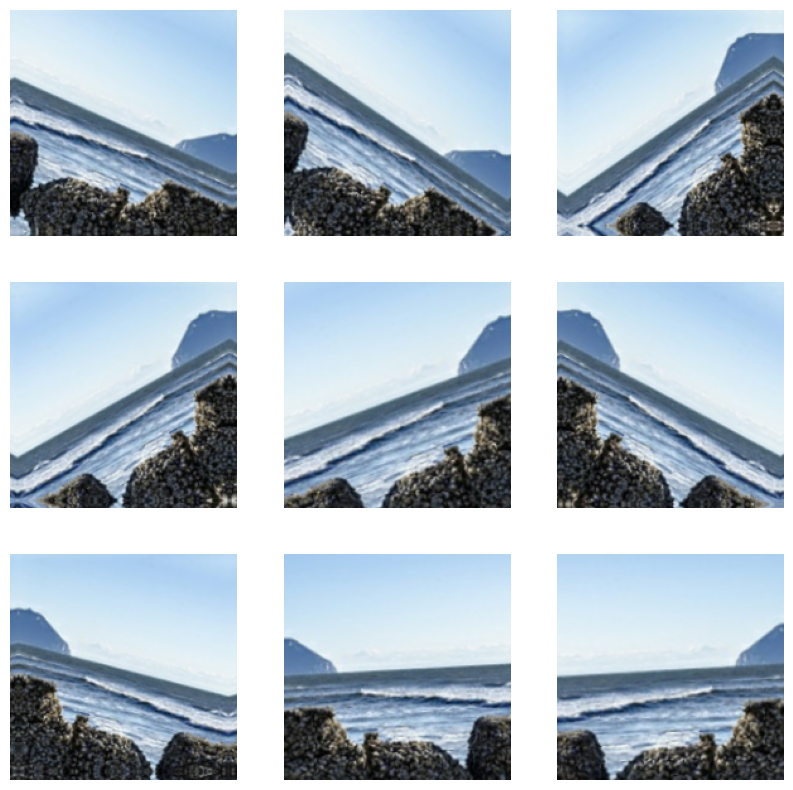

In [ ]:
plt.figure(figsize=(10,10))

for images, _ in train_ds.take(1):
  for i in range(9):
    augmented_images = data_augmentation(images)
    ax = plt.subplot(3,3,i+1)

    plt.imshow(augmented_images[2].numpy().astype("uint8"))
    plt.axis("off")

plt.show()



We will standardize our image input data.

The below code is to rescale an input in the [0, 255] range to [0, 1] range, by passing scale = 1./255.

In [ ]:
normalization_layer = layers.Rescaling(1./255)
normalized_ds = train_ds.map(lambda x,y: (normalization_layer(x), y))

image_batch, label_batch = next(iter(normalized_ds))

'''
A. train_ds.map()
- train_ds contains your training images and labels.
- .map() applies a function to every element (batch) in the dataset.
- Here, we use it to normalize all training images.
Think of .map() as applying the same operation to every batch.

B. lambda x, y:

A lambda is an anonymous (small, unnamed) function in Python.

Here:
- x represents the batch of images.
- y represents the corresponding batch of labels.

**A. iter(normalized_ds)
- iter() creates an iterator from the dataset.
- An iterator allows us to access dataset batches one by one.
B. next()
- next() retrieves the next available element from an iterator.
- Here, it retrieves the first batch.
C. image_batch, labels_batch

The first batch is divided into two parts:
- image_batch → Contains normalized images.
- labels_batch → Contains the original class labels.
'''

'\nA. train_ds.map()\n- train_ds contains your training images and labels.\n- .map() applies a function to every element (batch) in the dataset.\n- Here, we use it to normalize all training images.\nThink of .map() as applying the same operation to every batch.\n\nB. lambda x, y:\n\nA lambda is an anonymous (small, unnamed) function in Python.\n\nHere:\n- x represents the batch of images.\n- y represents the corresponding batch of labels.\n\n**A. iter(normalized_ds)\n- iter() creates an iterator from the dataset.\n- An iterator allows us to access dataset batches one by one.\nB. next()\n- next() retrieves the next available element from an iterator.\n- Here, it retrieves the first batch.\nC. image_batch, labels_batch\n\nThe first batch is divided into two parts:\n- image_batch → Contains normalized images.\n- labels_batch → Contains the original class labels.\n'

In [ ]:
image_batch

<tf.Tensor: shape=(32, 180, 180, 3), dtype=float32, numpy=
array([[[[0.38823533, 0.38823533, 0.38823533],
         [0.37058824, 0.37058824, 0.37058824],
         [0.35784316, 0.35784316, 0.35784316],
         ...,
         [0.32810348, 0.32810348, 0.32810348],
         [0.38627455, 0.38627455, 0.38627455],
         [0.36862746, 0.36862746, 0.36862746]],

        [[0.37647063, 0.37647063, 0.37647063],
         [0.36323532, 0.36323532, 0.36323532],
         [0.3536765 , 0.3536765 , 0.3536765 ],
         ...,
         [0.33300567, 0.33300567, 0.33300567],
         [0.38112748, 0.38112748, 0.38112748],
         [0.3745098 , 0.3745098 , 0.3745098 ]],

        [[0.35882354, 0.35882354, 0.35882354],
         [0.3539216 , 0.3539216 , 0.3539216 ],
         [0.34771246, 0.34771246, 0.34771246],
         ...,
         [0.33254296, 0.33254296, 0.33254296],
         [0.37083337, 0.37083337, 0.37083337],
         [0.37647063, 0.37647063, 0.37647063]],

        ...,

        [[0.01241838, 0.01241838,

In [ ]:
label_batch

<tf.Tensor: shape=(32,), dtype=int32, numpy=
array([5, 5, 0, 2, 1, 3, 0, 5, 2, 3, 4, 3, 4, 3, 1, 1, 4, 5, 2, 3, 2, 0,
       5, 3, 3, 4, 1, 4, 5, 2, 0, 1], dtype=int32)>

# Model Building

Build the Model
Let's build our model.

Here, we'll use a Sequential model with dense layer and other layers such as;

data_augmentation layer to add more information without adding extra data.

Rescaling layer to rescale the input to [0, 1] range.

## This below code creates a Convolutional Neural Network (CNN)

In [ ]:
model_sequential = Sequential([
    data_augmentation,
    layers.Rescaling(1./255),
    layers.Conv2D(16,3, padding = 'same', activation = 'relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(32,3, padding = 'same', activation = 'relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, padding = 'same', activation = 'relu'),
    layers.MaxPooling2D(),
    layers.Dropout(0.2),
    layers.Flatten(),
    layers.Dense(128, activation = 'relu'),
    layers.Dense(6, activation = "softmax")
])

- Parameter	Meaning
- 16-	Number of filters (What are filters?
A filter is a small matrix that moves across an image and detects patterns.
For example:
Edges,Lines,Corners,Textures)
- 3-	Filter size (3 × 3)
- padding='same'-	Maintains the image's height and width
- activation='relu' -	Applies ReLU activation

- 128: Number of neurons.
- activation='relu': Applies ReLU activation.
- layers.Dense(6, activation='softmax')
    * why 6? because we have 6 features labels

# 1. Feature extraction: Conv2D and MaxPooling2D layers.

# 2. Classification: Flatten and Dense layers.

# 3. Regularization and preprocessing: Data augmentation, Rescaling and Dropout.

In [ ]:
#This code is used to configure your CNN model before training it.
model_sequential.compile(loss = "sparse_categorical_crossentropy", optimizer = "adam", metrics = ["accuracy"])

- Parameter	Your choice	Purpose
- Loss	Sparse categorical crossentropy	Measures prediction error
- Optimizer	Adam	Updates weights to reduce error
- Metrics	Accuracy	Measures correct predictions

In [ ]:
model_sequential.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_1 (Sequential)       │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 180, 180, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 90, 90, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 90, 90, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 45, 45, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 45, 45, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 22, 22, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 22, 22, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 30976)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │     3,965,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,989,414 (15.22 MB)

 Trainable params: 3,989,414 (15.22 MB)

 Non-trainable params: 0 (0.00 B)

# **Train the model**

In [ ]:
epochs = 15
history = model_sequential.fit(train_ds,
                               validation_data = val_ds,
                               epochs= epochs)

In [ ]:
best_val_accuracy = max(history.history['val_accuracy'])

print("Best Validation Accuracy:",
      best_val_accuracy * 100, "%")

Best Validation Accuracy: 84.31931734085083 %


In [ ]:
best_epoch = (
    history.history['val_accuracy'].index(best_val_accuracy) + 1
)

print("Best Epoch:", best_epoch)

Best Epoch: 12


Evaluating the model performance

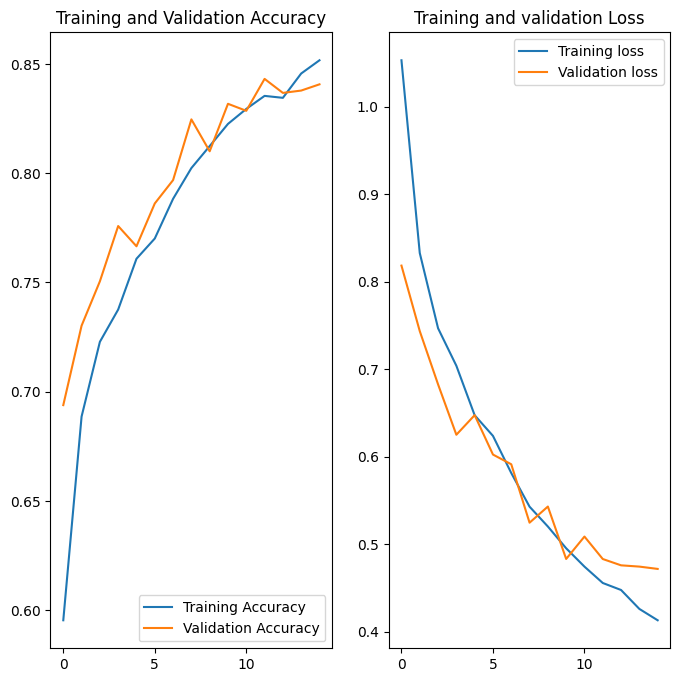

In [ ]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(epochs)

plt.figure(figsize = [8,8])
plt.subplot(1,2,1)
plt.plot(epochs_range, acc, label = 'Training Accuracy')
plt.plot(epochs_range, val_acc, label = "Validation Accuracy")
plt.legend(loc = 'lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(1,2,2)
plt.plot(epochs_range, loss, label = "Training loss")
plt.plot(epochs_range, val_loss, label = "Validation loss")
plt.legend(loc = 'upper right')
plt.title("Training and validation Loss")

plt.show();


1. Training and validation accuracy
Look at the left graph.

Training accuracy (blue line)
- Starts at approximately 66%.
- Gradually increases throughout the training process.
- Reaches approximately 84.66% by Epoch 15.
- Shows a small fluctuation around Epoch 14 but finishes with its highest training accuracy.
- This indicates that the CNN is progressively learning features and patterns from the training images.
Validation accuracy (orange line)
- Starts at approximately 72%.
- Gradually improves as training progresses.
- Shows some fluctuations between epochs.
- Achieves its highest validation accuracy of 83.61% at Epoch 14.
- Drops to approximately 82.22% in Epoch 15.
This indicates that the model's ability to classify unseen validation images improves during training, but its performance does not consistently improve towards the final epoch.
2. Training and validation loss
Look at the right graph.

Training loss (blue line)
- Starts at approximately 0.89.
- Continuously decreases throughout training.
- Reaches approximately 0.42 by Epoch 15.
- This indicates that the model is progressively reducing its prediction errors on the training dataset.
Validation loss (orange line)
- Starts at approximately 0.76.
- Initially decreases as the model learns.
- Shows a noticeable increase around Epoch 9.
- Reaches its lowest value of approximately 0.4865 at Epoch 14.
- Increases to approximately 0.5379 in Epoch 15.

* Metric	                    -Performance
* Best validation accuracy	  -83.61%
* Best epoch	                -14
* Final training accuracy	    -84.66%
* Final validation accuracy	  -82.22%
* Best validation loss	      -0.4865
* Final training loss	        -0.4218
* Final validation loss	      -0.5379

In [ ]:
model_sequential.save('/content/drive/MyDrive/2026DS Plan/Coomputer vision/cnn_image_model.keras')

In [ ]:
import os

model_path = '/content/drive/MyDrive/2026DS Plan/Coomputer vision/cnn_image_model.keras'

print("Model exists:", os.path.exists(model_path))

Model exists: True


In [ ]:
from tensorflow.keras.models import load_model

model_path = '/content/drive/MyDrive/2026DS Plan/Coomputer vision/cnn_image_model.keras'

loaded_model = load_model(model_path)

print("CNN model loaded successfully")


CNN model loaded successfully


# Transfer learning


We are importing the Resnet50 architecture as our model

We are not training the first layer of the resnet50 as it is already trained.

We are adding an extra layer at the end of resnet50 to get classification values.

We are using 20 epoch to train our model and early stopping to avoid overfitting.

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input

In [ ]:
num_epochs = 20
early_stop_petience = 3

In [ ]:
model2 = Sequential()
model2.add(ResNet50(include_top = False,
                    pooling = 'avg'))
#adding the last layer to get our  desired output.
model2.add(Dense(6, activation = 'softmax'))

#the first layer  is set  to trainable as false  as it is  already  trained.

model2.layers[0].trainable = False

In [ ]:
model2.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)           │ (None, 2048)           │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 6)              │        12,294 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,600,006 (90.03 MB)

 Trainable params: 12,294 (48.02 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

# Using Adam as our optimizer and sparse categorical crossentropy as our loss function for multi-class classification.

In [ ]:
model2.compile(optimizer = 'adam',
               loss = 'sparse_categorical_crossentropy',
               metrics = ['accuracy'])


* Defining  EarlyStopping parameters to avoid overfitting

In [ ]:
cb_early_stopper = EarlyStopping(monitor = 'val_loss', patience= early_stop_petience)

In [ ]:
fit_history = model2.fit(train_ds,
                        steps_per_epoch = 10,
                        epochs = num_epochs,
                        validation_data = val_ds,
                        validation_steps = 10,
                        callbacks = [cb_early_stopper])

Epoch 1/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 30s 678ms/step - accuracy: 0.5125 - loss: 1.4181 - val_accuracy: 0.6031 - val_loss: 0.9614
Epoch 2/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 130ms/step - accuracy: 0.6781 - loss: 0.7641 - val_accuracy: 0.7156 - val_loss: 0.6607
Epoch 3/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 131ms/step - accuracy: 0.8281 - loss: 0.5145 - val_accuracy: 0.8250 - val_loss: 0.4554
Epoch 4/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 131ms/step - accuracy: 0.8406 - loss: 0.4469 - val_accuracy: 0.8594 - val_loss: 0.4188
Epoch 5/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 136ms/step - accuracy: 0.8219 - loss: 0.5040 - val_accuracy: 0.8500 - val_loss: 0.3910
Epoch 6/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 131ms/step - accuracy: 0.8562 - loss: 0.4018 - val_accuracy: 0.8469 - val_loss: 0.4109
Epoch 7/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 131ms/step - accuracy: 0.9000 - loss: 0.3148 - val_accuracy: 0.8469 - val_loss: 0.3810
Epoch 8/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 138ms/step - accuracy: 0.8781 - loss: 0.3627 - val_accuracy: 0

The below code is used to get all the locations and names of images and store it in a list `x_test`.

In [ ]:
x_test =[]

directory = r'./test'
for filename in  os.listdir(directory):
  if filename.endswith(".jpg") or  filename.endswith(".png"):
    test_data = os.path.join(directory, filename)
    x_test.append(test_data)
  else:
    continue


The above created list of images is then looped and we predict the respective labels using the following code.

The prediction is stored in a dictionary with the file location containing the name of the image.

In [ ]:
x_test

['./test/22933.jpg',
 './test/20619.jpg',
 './test/20857.jpg',
 './test/23761.jpg',
 './test/21717.jpg',
 './test/21222.jpg',
 './test/23016.jpg',
 './test/20678.jpg',
 './test/24056.jpg',
 './test/22599.jpg',
 './test/21507.jpg',
 './test/22160.jpg',
 './test/22569.jpg',
 './test/23982.jpg',
 './test/23138.jpg',
 './test/20074.jpg',
 './test/20763.jpg',
 './test/20904.jpg',
 './test/21248.jpg',
 './test/20109.jpg',
 './test/21036.jpg',
 './test/20075.jpg',
 './test/21779.jpg',
 './test/20265.jpg',
 './test/21381.jpg',
 './test/23760.jpg',
 './test/21045.jpg',
 './test/20657.jpg',
 './test/20648.jpg',
 './test/22228.jpg',
 './test/20115.jpg',
 './test/21410.jpg',
 './test/21217.jpg',
 './test/21367.jpg',
 './test/23969.jpg',
 './test/20154.jpg',
 './test/23254.jpg',
 './test/22385.jpg',
 './test/22336.jpg',
 './test/24196.jpg',
 './test/24075.jpg',
 './test/20395.jpg',
 './test/22141.jpg',
 './test/22314.jpg',
 './test/20634.jpg',
 './test/23930.jpg',
 './test/23715.jpg',
 './test/2067

In [ ]:
submission_file = {}
for i in x_test:
  img = tf.keras.preprocessing.image.load_img(i,
                                              target_size = (img_height,img_width))
  img_array = tf.keras.preprocessing.image.img_to_array(img)
  img_array = tf.expand_dims(img_array, 0)
  predictions = model2.predict(img_array)

  print("*"*50)
  print("All predictions : ",predictions)
  print("Prediction with highest confidence", np.argmax(predictions[0]))
  print("Class  name corresponding  to the predict  with the highest  confidence :", class_names[np.argmax(predictions[0])])
  print("*"*50)
  y_pred = class_names[np.argmax(predictions[0])]
  submission_file[i] = y_pred

Streaming output truncated to the last 5000 lines.
Class  name corresponding  to the predict  with the highest  confidence : sea
**************************************************
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 113ms/step
**************************************************
All predictions :  [[9.8321658e-01 1.6299340e-04 7.2258775e-04 3.8326546e-03 1.6562105e-03
  1.0409025e-02]]
Prediction with highest confidence 0
Class  name corresponding  to the predict  with the highest  confidence : buildings
**************************************************
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step
**************************************************
All predictions :  [[4.7416198e-01 1.3055395e-04 5.8033911e-04 1.4303672e-03 4.1056029e-03
  5.1959115e-01]]
Prediction with highest confidence 5
Class  name corresponding  to the predict  with the highest  confidence : street
**************************************************
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step
********************************************

Here we are converting the dictionary to dataframe and renaming the columns."

In [ ]:
submission_file

{'./test/22933.jpg': 'street',
 './test/20619.jpg': 'forest',
 './test/20857.jpg': 'mountain',
 './test/23761.jpg': 'mountain',
 './test/21717.jpg': 'glacier',
 './test/21222.jpg': 'glacier',
 './test/23016.jpg': 'glacier',
 './test/20678.jpg': 'sea',
 './test/24056.jpg': 'mountain',
 './test/22599.jpg': 'mountain',
 './test/21507.jpg': 'sea',
 './test/22160.jpg': 'glacier',
 './test/22569.jpg': 'forest',
 './test/23982.jpg': 'buildings',
 './test/23138.jpg': 'street',
 './test/20074.jpg': 'sea',
 './test/20763.jpg': 'glacier',
 './test/20904.jpg': 'buildings',
 './test/21248.jpg': 'glacier',
 './test/20109.jpg': 'mountain',
 './test/21036.jpg': 'mountain',
 './test/20075.jpg': 'street',
 './test/21779.jpg': 'buildings',
 './test/20265.jpg': 'sea',
 './test/21381.jpg': 'street',
 './test/23760.jpg': 'forest',
 './test/21045.jpg': 'sea',
 './test/20657.jpg': 'mountain',
 './test/20648.jpg': 'buildings',
 './test/22228.jpg': 'street',
 './test/20115.jpg': 'sea',
 './test/21410.jpg': 'str

In [ ]:
your_df_from_dict = pd.DataFrame.from_dict(submission_file, orient = 'index')


In [ ]:
your_df_from_dict

,0
./test/22933.jpg,street
./test/20619.jpg,forest
./test/20857.jpg,mountain
./test/23761.jpg,mountain
./test/21717.jpg,glacier
...,...
./test/20863.jpg,street
./test/22134.jpg,buildings
./test/22276.jpg,mountain
./test/22346.jpg,mountain


In [ ]:
your_df_from_dict =your_df_from_dict.reset_index()
your_df_from_dict

,index,0
0,./test/22933.jpg,street
1,./test/20619.jpg,forest
2,./test/20857.jpg,mountain
3,./test/23761.jpg,mountain
4,./test/21717.jpg,glacier
...,...,...
2995,./test/20863.jpg,street
2996,./test/22134.jpg,buildings
2997,./test/22276.jpg,mountain
2998,./test/22346.jpg,mountain


In [ ]:
subm = your_df_from_dict.rename(columns = {'index':'Image_Name',0:'labels'})

In [ ]:
subm

,Image_Name,labels
0,./test/22933.jpg,street
1,./test/20619.jpg,forest
2,./test/20857.jpg,mountain
3,./test/23761.jpg,mountain
4,./test/21717.jpg,glacier
...,...,...
2995,./test/20863.jpg,street
2996,./test/22134.jpg,buildings
2997,./test/22276.jpg,mountain
2998,./test/22346.jpg,mountain


In [ ]:
subm['Image_Name'][0]

'./test/22933.jpg'

**The below code will extract only the image name with its extension from the image location using python regular expression library.**

In [ ]:
import re
import pandas as pd
lis = []
for j in subm['Image_Name']:
  data=re.findall(r'[^\/]+(?=)',j)[-1]
  lis.append(data)
df = pd.DataFrame(lis, columns = ['Image_Name'])
frames = [df,label]
result = pd.concat(frames, axis =1)

NameError: name 'label' is not defined

In [ ]:
result

In [ ]:
result.to_csv('submission.csv', header = False, index = False)

In [ ]:
result

In [ ]:
y_df = pd.read_excel("/content/drive/MyDrive/2026DS Plan/Coomputer vision/Nature_y_test.xlsx",names = ["Image_Name","labels"])
y_df

In [138]:
data= y_df.merge(result, on = 'Image_Name', how = 'left')
data

,Image_Name,labels,labels_y
0,24099.jpg,sea,sea
1,23003.jpg,buildings,buildings
2,23624.jpg,sea,sea
3,23868.jpg,mountain,mountain
4,22232.jpg,street,street
...,...,...,...
2995,24196.jpg,glacier,glacier
2996,20362.jpg,glacier,glacier
2997,20166.jpg,forest,forest
2998,20801.jpg,forest,forest


In [ ]:
print("Accuracy Score of  test data  is  : ",accuracy_score(data['labels_x'],data['labels_y'])*100,"%")

In [139]:
num_epochs = 20

fit_history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=num_epochs,
    callbacks=[cb_early_stopper, checkpoint]
)

Epoch 1/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 17s 48ms/step - accuracy: 0.9295 - loss: 0.1893 - val_accuracy: 0.9077 - val_loss: 0.2541
Epoch 2/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 12s 34ms/step - accuracy: 0.9289 - loss: 0.1851 - val_accuracy: 0.9113 - val_loss: 0.2536
Epoch 3/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 21s 34ms/step - accuracy: 0.9320 - loss: 0.1825 - val_accuracy: 0.9141 - val_loss: 0.2521
Epoch 4/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 20s 34ms/step - accuracy: 0.9300 - loss: 0.1777 - val_accuracy: 0.9120 - val_loss: 0.2623
Epoch 5/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 20s 33ms/step - accuracy: 0.9298 - loss: 0.1784 - val_accuracy: 0.9102 - val_loss: 0.2659


In [140]:
import pandas as pd

cm_df = pd.DataFrame(
    cm,
    index=classes,
    columns=classes
)

print(cm_df)

           buildings  forest  glacier  mountain  sea  street
buildings        395       0        0         1    0      41
forest             0     472        1         0    0       1
glacier            0       1      494        43   14       1
mountain           0       0       82       433    9       1
sea                1       0       14         5  490       0
street            23       0        0         0    1     477


In [141]:
import os

model_path = '/content/drive/MyDrive/2026DS Plan/Coomputer vision/best_mobilenetv2.keras'

if os.path.exists(model_path):
    print("MobileNetV2 checkpoint found!")
    print("File size:", round(os.path.getsize(model_path) / (1024 * 1024), 2), "MB")
else:
    print("MobileNetV2 checkpoint not found.")

MobileNetV2 checkpoint found!
File size: 9.26 MB


In [142]:
import tensorflow as tf

best_mobilenet = tf.keras.models.load_model(
    '/content/drive/MyDrive/2026DS Plan/Coomputer vision/best_mobilenetv2.keras'
)

print("MobileNetV2 model loaded successfully!")

MobileNetV2 model loaded successfully!


In [143]:
test_loss, test_accuracy = best_mobilenet.evaluate(
    x_test,
    y_test,
    batch_size=32
)

print("MobileNetV2 Test Loss:", test_loss)
print("MobileNetV2 Test Accuracy:", test_accuracy * 100, "%")

94/94 ━━━━━━━━━━━━━━━━━━━━ 20s 139ms/step - accuracy: 0.9030 - loss: 0.2544
MobileNetV2 Test Loss: 0.25442615151405334
MobileNetV2 Test Accuracy: 90.2999997138977 %


In [144]:
from sklearn.metrics import classification_report, confusion_matrix
import pandas as pd

predictions_mobilenet = best_mobilenet.predict(x_test)

y_pred_mobilenet = predictions_mobilenet.argmax(axis=1)

print(classification_report(
    y_test,
    y_pred_mobilenet,
    target_names=class_names
))

cm_mobilenet = confusion_matrix(y_test, y_pred_mobilenet)

cm_df = pd.DataFrame(
    cm_mobilenet,
    index=class_names,
    columns=class_names
)

print(cm_df)

94/94 ━━━━━━━━━━━━━━━━━━━━ 12s 57ms/step
              precision    recall  f1-score   support

   buildings       0.90      0.94      0.92       437
      forest       0.99      0.99      0.99       474
     glacier       0.85      0.80      0.83       553
    mountain       0.86      0.82      0.84       525
         sea       0.88      0.98      0.93       510
      street       0.94      0.91      0.93       501

    accuracy                           0.90      3000
   macro avg       0.90      0.91      0.90      3000
weighted avg       0.90      0.90      0.90      3000

           buildings  forest  glacier  mountain  sea  street
buildings        410       2        0         0    0      25
forest             1     470        2         1    0       0
glacier            1       2      442        65   42       1
mountain           3       3       64       431   23       1
sea                1       0        7         1  501       0
street            40       0        2         2   

In [145]:
print("MobileNetV2 Training Accuracy:",
      max(fit_history.history['accuracy']) * 100)

print("MobileNetV2 Validation Accuracy:",
      max(fit_history.history['val_accuracy']) * 100)

MobileNetV2 Training Accuracy: 93.20448637008667
MobileNetV2 Validation Accuracy: 91.41126275062561


In [146]:
print("EfficientNetB0 Training Accuracy:",
      max(fit_history.history['accuracy']) * 100)

print("EfficientNetB0 Validation Accuracy:",
      max(fit_history.history['val_accuracy']) * 100)

EfficientNetB0 Training Accuracy: 93.20448637008667
EfficientNetB0 Validation Accuracy: 91.41126275062561


In [147]:
print("ResNet50 Training Accuracy:",
      max(history.history['accuracy']) * 100)

print("ResNet50 Validation Accuracy:",
      max(history.history['val_accuracy']) * 100)

ResNet50 Training Accuracy: 89.32133913040161
ResNet50 Validation Accuracy: 84.8895251750946


In [148]:
print(max(fit_history_efficientnet.history['accuracy']) * 100)

NameError: name 'fit_history_efficientnet' is not defined

In [149]:
fit_history = model.fit(...)

ValueError: Unrecognized data type: x=Ellipsis (of type <class 'ellipsis'>)

In [150]:
%whos

Variable                 Type                      Data/Info
------------------------------------------------------------
ConfusionMatrixDisplay   type                      <class 'sklearn.metrics._<...>.ConfusionMatrixDisplay'>
Conv2D                   type                      <class 'tensorflow.python<...>rs.convolutional.Conv2D'>
Dense                    type                      <class 'keras.src.layers.core.dense.Dense'>
EarlyStopping            type                      <class 'keras.src.callbac<...>_stopping.EarlyStopping'>
EfficientNetB0           function                  <function EfficientNetB0 at 0x7fe5946b3420>
Flatten                  type                      <class 'tensorflow.python<...>ras.layers.core.Flatten'>
LabelEncoder             type                      <class 'sklearn.preproces<...>ing._label.LabelEncoder'>
MobileNetV2              function                  <function MobileNetV2 at 0x7fe5946d6020>
ModelCheckpoint          type                      <class 'ke

In [151]:
print("acc:", acc)
print("val_acc:", val_acc)

acc: [0.5953865051269531, 0.688635528087616, 0.7228357791900635, 0.7376202344894409, 0.7608656883239746, 0.7701282501220703, 0.7882971167564392, 0.8023690581321716, 0.8124331831932068, 0.8225864171981812, 0.8294442296028137, 0.8354114890098572, 0.8345208168029785, 0.8456537127494812, 0.8517100214958191]
val_acc: [0.6938703060150146, 0.7302209734916687, 0.7505345940589905, 0.7758374810218811, 0.7665716409683228, 0.7861725091934204, 0.796863853931427, 0.8246614336967468, 0.8100498914718628, 0.8317890167236328, 0.8285816311836243, 0.8431931734085083, 0.8367783427238464, 0.8378474712371826, 0.8406984806060791]


In [152]:
print("Training Accuracy:", max(acc) * 100, "%")
print("Best Validation Accuracy:", max(val_acc) * 100, "%")

Training Accuracy: 85.17100214958191 %
Best Validation Accuracy: 84.31931734085083 %


In [153]:
print("History training accuracy:",
      max(history.history['accuracy']) * 100)

print("History validation accuracy:",
      max(history.history['val_accuracy']) * 100)

History training accuracy: 89.32133913040161
History validation accuracy: 84.8895251750946


# Nature Image Classification Using Transfer Learning

## 1. Project Overview

**Objective:** Build a multi-class image classification model to identify six categories of nature and urban scenes using deep learning and transfer learning.

**Dataset:** 6 classes
- Buildings
- Forest
- Glacier
- Mountain
- Sea
- Street

**Image dimensions:** 180 × 180 × 3 (RGB)

**Test dataset:** 3,000 images

## 2. Models Implemented

Three pretrained CNN architectures were evaluated:

1. ResNet50
2. EfficientNetB0
3. MobileNetV2

Transfer learning was used by freezing the pretrained convolutional base and training a custom classification head with six output classes.

## 3. Model Performance Comparison

| Metric | ResNet50 | EfficientNetB0 | MobileNetV2 |
|---|---:|---:|---:|
| Training Accuracy | 89.32% | Not recovered | 93.20% |
| Best Validation Accuracy | 84.89% | 93.51% | 91.41% |
| Test Accuracy | 86.96% | **92.03%** | 90.30% |
| Test Loss | Not recorded | 0.2081 | 0.2544 |
| Model Size | Not recorded | Not recorded | 9.26 MB |

*Note: EfficientNetB0's 93.51% is its best recorded validation accuracy. Its training accuracy was not recovered from the notebook. Model sizes and training times were not available for all three architectures.*

## 4. Classification Performance

### EfficientNetB0

| Class | Precision | Recall | F1-score |
|---|---:|---:|---:|
| Buildings | 0.94 | 0.90 | 0.92 |
| Forest | 1.00 | 1.00 | 1.00 |
| Glacier | 0.84 | 0.89 | 0.86 |
| Mountain | 0.90 | 0.82 | 0.86 |
| Sea | 0.95 | 0.96 | 0.96 |
| Street | 0.92 | 0.95 | 0.93 |

### MobileNetV2

| Class | Precision | Recall | F1-score |
|---|---:|---:|---:|
| Buildings | 0.90 | 0.94 | 0.92 |
| Forest | 0.99 | 0.99 | 0.99 |
| Glacier | 0.85 | 0.80 | 0.83 |
| Mountain | 0.86 | 0.82 | 0.84 |
| Sea | 0.88 | 0.98 | 0.93 |
| Street | 0.94 | 0.91 | 0.93 |

## 5. Confusion Matrix Observations

The main classification challenges were:

- Glacier and mountain images were frequently confused with each other.
- Buildings and street images also showed some misclassification.
- Forest images achieved excellent classification performance across both EfficientNetB0 and MobileNetV2.

EfficientNetB0 correctly classified 2,761 out of 3,000 test images.

## 6. Final Model Selection

**Selected Model: EfficientNetB0**

Reasons:
- Highest test accuracy of 92.03%.
- Lowest recorded test loss of 0.2081.
- Strong class-wise performance.
- Better overall test performance than ResNet50 and MobileNetV2.

## 7. Conclusion

This project demonstrates the application of transfer learning for multi-class image classification using three pretrained CNN architectures.

EfficientNetB0 achieved the best overall test performance, with 92.03% accuracy, followed by MobileNetV2 at 90.30% and ResNet50 at 86.96%.

The experiments highlight the importance of architecture selection, transfer learning, model evaluation, and class-wise performance analysis in developing reliable computer vision solutions.


In [154]:
import os

model_path = '/content/drive/MyDrive/2026DS Plan/Coomputer vision/best_efficientnetb0.keras'

print("Model exists:", os.path.exists(model_path))

print("Model size:",
      round(os.path.getsize(model_path) / (1024 * 1024), 2), "MB")

Model exists: True
Model size: 16.34 MB


In [155]:
from google.colab import files

files.download(model_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>